# IRIS CLASSIFICATION USING MACHINE LEARNING

## BUSINESS UNDERSTANDING

The Iris dataset contains measurements of iris flowers. The objective is to use the flower measurements to identify the species of an iris flower.

The input features are:
- Sepal Length
- Sepal Width
- Petal Length
- Petal Width

The target variable is the Iris species.


## PROBLEM STATEMENT

The objective of this project is to develop a machine learning classification model that predicts the species of an Iris flower based on its sepal and petal measurements. The trained model will be deployed through a Gradio web interface so that users can enter flower measurements and receive a predicted species.


## PROJECT OBJECTIVES

1. Load and understand the Iris dataset.
2. Understand the dataset structure, features, and target variable.
3. Perform data cleaning and exploratory data analysis (EDA).
4. Check missing values and duplicate records.
5. Analyze relationships among the numerical features.
6. Select relevant features and split the data into training and testing sets.
7. Train and compare multiple classification models.
8. Evaluate models using Accuracy, Precision, Recall, and F1 Score.
9. Save the best model and its preprocessing pipeline.
10. Deploy the model using Gradio.
11. Test the deployed application and prepare the final submission.

## TYPE OF MACHINE LEARNING PROBLEM

- Learning type : Supervised learning

- Problem type : Multiclass Classification

- Why classification? Because the output is a category — the species of the Iris flower — rather than a continuous numerical value.

## EXPECTED OUTPUT

- At the end of this project, a user should be able to enter Iris flower measurements into a simple web application and receive the predicted species.

- The possible classes in this dataset are Iris-setosa, Iris-versicolor, and Iris-virginica.

## Dataset Collection and Project Setup

For this project, we use the provided `IRIS.csv` dataset. It contains 150 observations and five columns: four numerical flower measurements and one categorical target column named `species`.

## Installing Required Libraries

In [2]:
%pip install pandas numpy matplotlib seaborn scikit-learn joblib gradio

Note: you may need to restart the kernel to use updated packages.


These libraries will be used for the following purposes:

- Pandas — Load and manipulate data
- NumPy — Numerical operations
- Matplotlib — Create charts
- Seaborn — Statistical visualizations
- Scikit-learn — Preprocessing, model training, and evaluation
- Joblib — Save and load the trained model
- Gradio — Build the interactive web application


## Importing Required Libraries

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Loading The Dataset

In [7]:
df = pd.read_csv("IRIS.csv")

print("Dataset Loaded Successfully!")

Dataset Loaded Successfully!


In [8]:
df.shape

(150, 5)

In [5]:
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


## Data Understanding and EDA

EDA helps us understand the Iris dataset before training a machine learning model. We will investigate the dataset's structure, data quality, distributions, and relationships between flower measurements and species.

## Dimensions

In [9]:
print("Number of rows:", df.shape[0])

print("Number of columns:", df.shape[1])

Number of rows: 150
Number of columns: 5


## Displaying the first and last records

In [10]:
df.head()  # first 5 records

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


In [11]:
df.tail()  # last 5 records

,sepal_length,sepal_width,petal_length,petal_width,species
145,6.7,3.0,5.2,2.3,Iris-virginica
146,6.3,2.5,5.0,1.9,Iris-virginica
147,6.5,3.0,5.2,2.0,Iris-virginica
148,6.2,3.4,5.4,2.3,Iris-virginica
149,5.9,3.0,5.1,1.8,Iris-virginica


## Inspecting column names and data types

In [12]:
print("Column names:")

print(df.columns.tolist())

Column names:
['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']


In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


## Checking missing values

In [14]:
missing_count = df.isnull().sum()

missing_count

sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

## Checking duplicate records

In [15]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 3


## Numerical Summaries

In [16]:
df.describe()

,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.054000,3.758667,1.198667
std,0.828066,0.433594,1.764420,0.763161
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


This displays the count, mean, standard deviation, minimum, quartiles, and maximum for the numerical Iris measurements.

For example:
- Mean tells us the average measurement.
- 50% represents the median.
- Min and max reveal the range.
- Quartiles help us understand the spread of the observations.

## Summarizing categorical column

In [17]:
df.describe(include='object')

,species
count,150
unique,3
top,Iris-setosa
freq,50


- This helps us identify the number of unique Iris species and the most frequent species in the dataset.

## Identifying the target variable

In [18]:
print("Possible target columns:")

print([col for col in df.columns if col.lower() in ["species", "target", "class"]])

Possible target columns:
['species']


## Data Visualization

### Understanding the Data Quality

In [19]:
print("Duplicate rows:", df.duplicated().sum())

display(df[df.duplicated(keep=False)].head(10))

Duplicate rows: 3


,sepal_length,sepal_width,petal_length,petal_width,species
9,4.9,3.1,1.5,0.1,Iris-setosa
34,4.9,3.1,1.5,0.1,Iris-setosa
37,4.9,3.1,1.5,0.1,Iris-setosa
101,5.8,2.7,5.1,1.9,Iris-virginica
142,5.8,2.7,5.1,1.9,Iris-virginica


In [20]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
sepal_length,150.0,5.843333,0.828066,4.3,5.1,5.80,6.4,7.9
sepal_width,150.0,3.054000,0.433594,2.0,2.8,3.00,3.3,4.4
petal_length,150.0,3.758667,1.764420,1.0,1.6,4.35,5.1,6.9
petal_width,150.0,1.198667,0.763161,0.1,0.3,1.30,1.8,2.5


## Class Distribution

In [21]:
print(df["species"].value_counts())

species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64


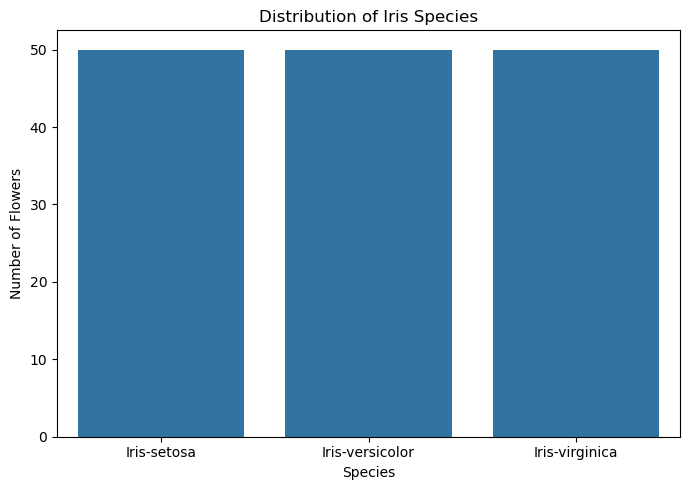

In [22]:
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="species")
plt.title("Distribution of Iris Species")
plt.xlabel("Species")
plt.ylabel("Number of Flowers")
plt.tight_layout()
plt.show()

- This chart shows how many observations are available for each Iris species.

## Feature Distributions

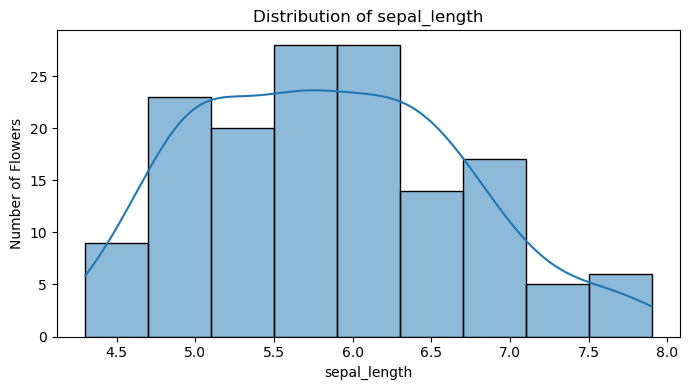

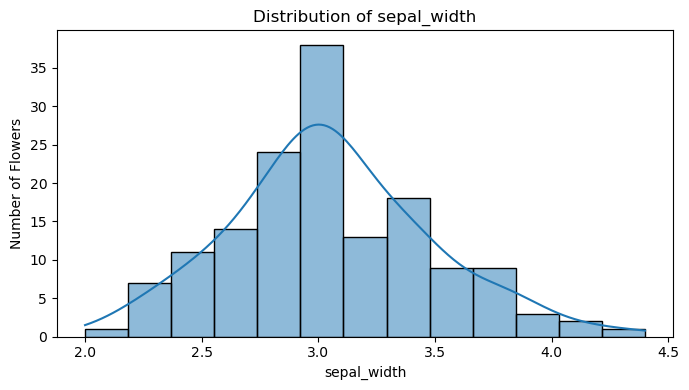

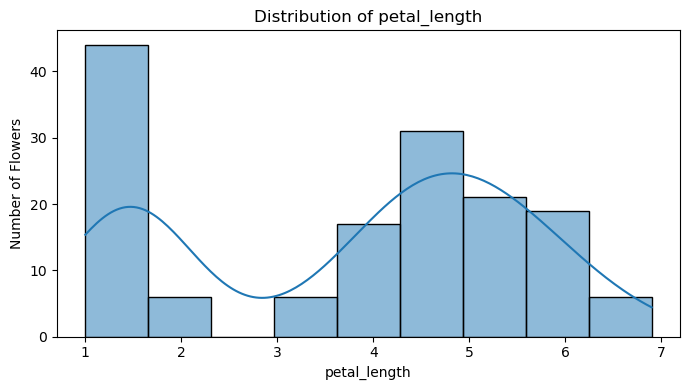

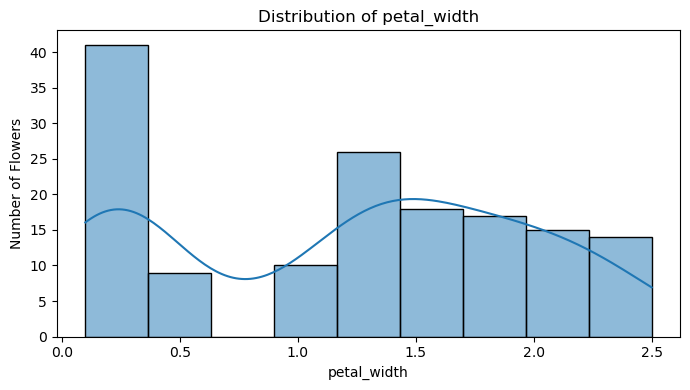

In [23]:
features = ["sepal_length", "sepal_width", "petal_length", "petal_width"]

for col in features:
    plt.figure(figsize=(7, 4))
    sns.histplot(data=df, x=col, kde=True)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Number of Flowers")
    plt.tight_layout()
    plt.show()

## Pairwise Relationships

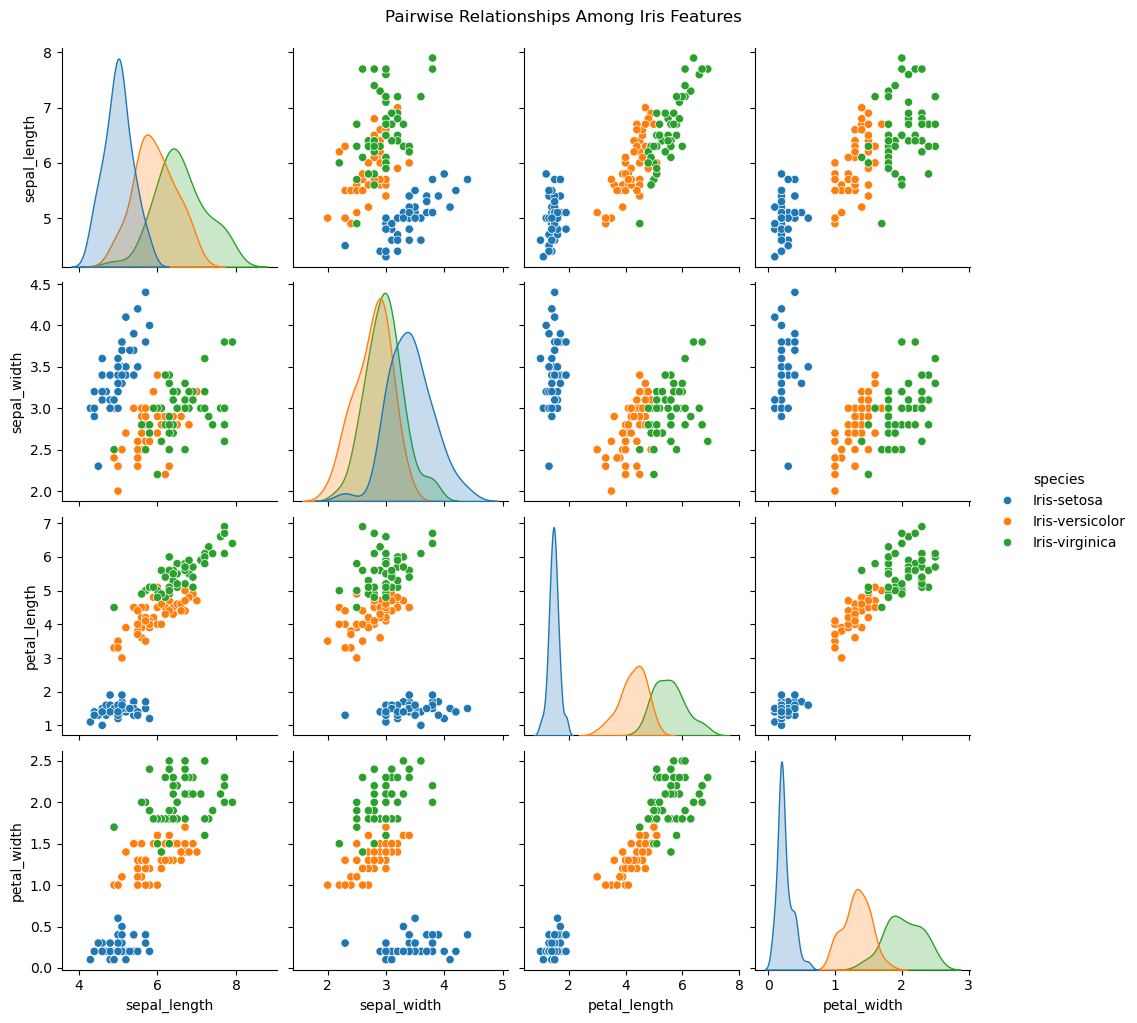

In [24]:
sns.pairplot(df, hue="species")

plt.suptitle("Pairwise Relationships Among Iris Features", y=1.02)
plt.show()

- Pair plots help identify which measurements separate the Iris species most clearly.

## Boxplots by Species

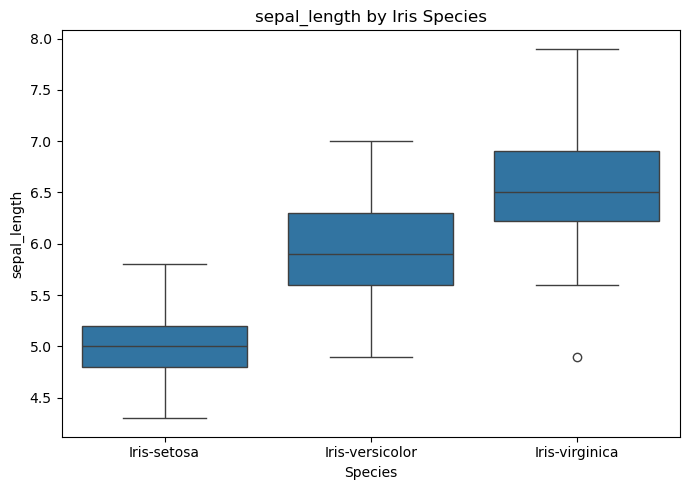

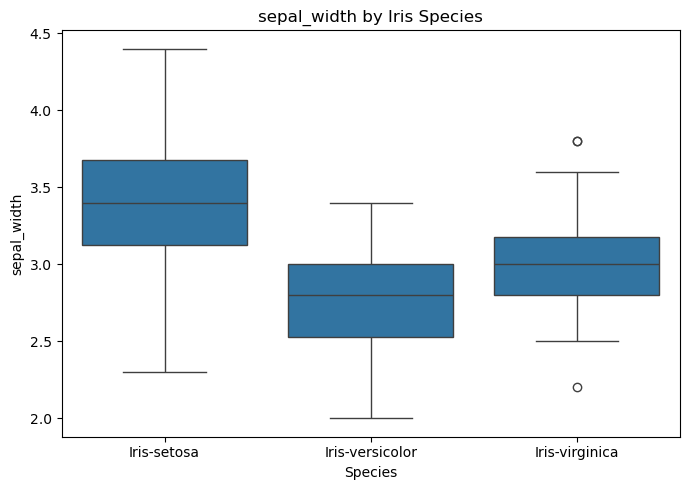

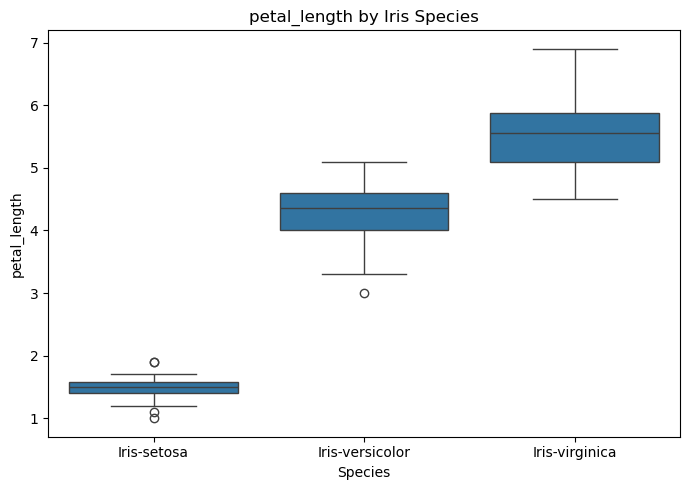

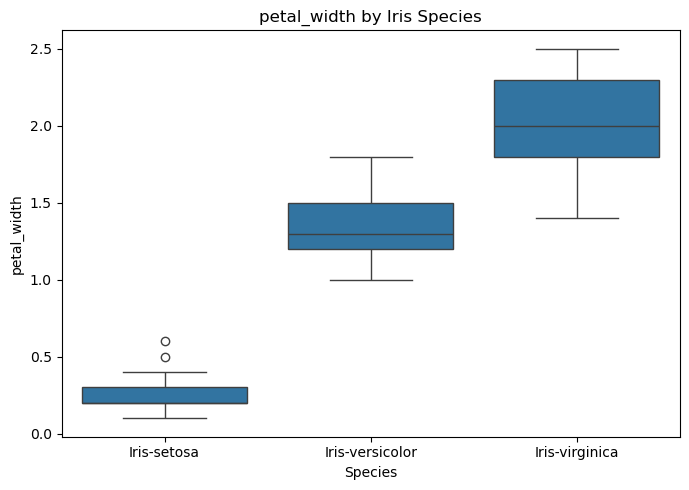

In [25]:
for col in features:
    plt.figure(figsize=(7, 5))
    sns.boxplot(data=df, x="species", y=col)
    plt.title(f"{col} by Iris Species")
    plt.xlabel("Species")
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()

## Correlation Between Numerical Features

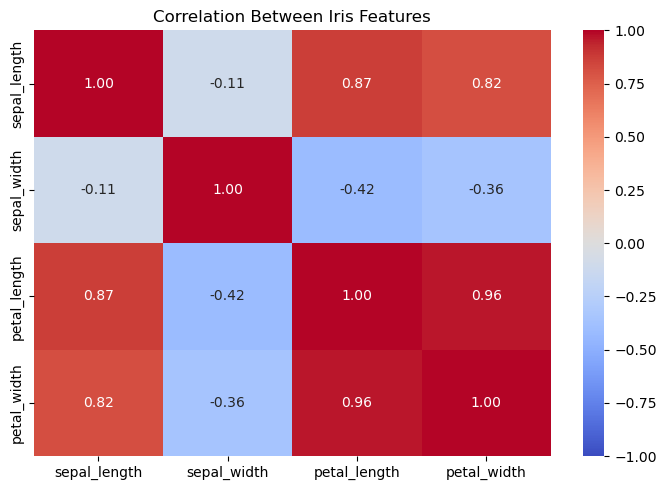

In [26]:
numeric_df = df.select_dtypes(include="number")

plt.figure(figsize=(7, 5))
sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)
plt.title("Correlation Between Iris Features")
plt.tight_layout()
plt.show()

- Correlation ranges from -1 to +1. Values near +1 indicate a strong positive linear relationship, while values near -1 indicate a strong negative linear relationship.

## Duplicate records

In [27]:
duplicates = df[df.duplicated(keep=False)]

print("Rows involved in duplicate groups:", len(duplicates))

display(duplicates.head(10))

Rows involved in duplicate groups: 5


,sepal_length,sepal_width,petal_length,petal_width,species
9,4.9,3.1,1.5,0.1,Iris-setosa
34,4.9,3.1,1.5,0.1,Iris-setosa
37,4.9,3.1,1.5,0.1,Iris-setosa
101,5.8,2.7,5.1,1.9,Iris-virginica
142,5.8,2.7,5.1,1.9,Iris-virginica


- Exact duplicate rows can give repeated observations extra weight during model training. They should be reviewed before removal.

In [28]:
df = df.drop_duplicates().copy()

print("Dataset shape after removing duplicates:", df.shape)
print("Remaining duplicate rows:", df.duplicated().sum())

Dataset shape after removing duplicates: (147, 5)
Remaining duplicate rows: 0


## Final EDA checks

In [29]:
print("Feature ranges:")
for col in ["sepal_length", "sepal_width", "petal_length", "petal_width"]:
    print(f"{col}: {df[col].min()} - {df[col].max()}")

print("\nSpecies:")
print(df["species"].value_counts())

Feature ranges:
sepal_length: 4.3 - 7.9
sepal_width: 2.0 - 4.4
petal_length: 1.0 - 6.9
petal_width: 0.1 - 2.5

Species:
species
Iris-versicolor    50
Iris-virginica     49
Iris-setosa        48
Name: count, dtype: int64


## Data preprocessing, feature selection, and train-test split

### Separate X and y

In [30]:
model_df = df.copy()

feature_columns = [
    "sepal_length",
    "sepal_width",
    "petal_length",
    "petal_width"
]

X = model_df[feature_columns].copy()
y = model_df["species"].copy()

print("Feature dataset shape:", X.shape)
print("Target dataset shape:", y.shape)

display(X.head())
display(y.head())

Feature dataset shape: (147, 4)
Target dataset shape: (147,)


,sepal_length,sepal_width,petal_length,petal_width
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


0    Iris-setosa
1    Iris-setosa
2    Iris-setosa
3    Iris-setosa
4    Iris-setosa
Name: species, dtype: object

Understanding the terms:

- X contains the flower measurements used by the model.
- y contains the correct Iris species that the model learns to predict.


## Split the data into training and testing sets

We'll use an 80/20 split.

- 80% training data: Used to train the models.
- 20% testing data: Kept separate to evaluate the models on unseen records.


#### `random_state=42` makes the split reproducible. 

#### `stratify=y` keeps the class proportions similar in the training and testing sets.

In [32]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training targets:", y_train.shape)
print("Testing targets:", y_test.shape)

Training features: (117, 4)
Testing features: (30, 4)
Training targets: (117,)
Testing targets: (30,)


## Prepare the preprocessing pipeline

- Machine learning models require clean numerical inputs. We'll use `SimpleImputer` to handle any missing numerical values and `StandardScaler` for models that benefit from feature scaling.

- The preprocessing pipeline is fitted only on the training data to avoid data leakage from the test set.


In [33]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

numeric_features = feature_columns

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


## Model Building, Evaluation, and Selection

In [34]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

## Build complete model pipelines

In [35]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42,
        max_depth=5
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    )
}

pipelines = {}

for name, model in models.items():
    pipelines[name] = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])

print("All model pipelines created successfully!")

All model pipelines created successfully!


### Why use a pipeline?

A pipeline combines preprocessing and model prediction into one object. The same preprocessing steps are automatically applied during training and prediction.

## Train the models

In [36]:
for name, pipeline in pipelines.items():
    print(f"Training {name}...")
    pipeline.fit(X_train, y_train)
    print(f"{name} trained successfully!\n")

Training Logistic Regression...
Logistic Regression trained successfully!

Training Decision Tree...
Decision Tree trained successfully!

Training Random Forest...
Random Forest trained successfully!



## Evaluate the models

We will compare the models using:

- Accuracy — proportion of correct predictions.
- Precision — how many predicted instances of a class are actually that class.
- Recall — how many actual instances of a class are correctly identified.
- F1 Score — balance between precision and recall.

For these metrics, higher values are generally better.

In [38]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

results = []

for name, pipeline in pipelines.items():
    y_pred = pipeline.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, average="weighted", zero_division=0)
    recall = recall_score(y_test, y_pred, average="weighted", zero_division=0)
    f1 = f1_score(y_test, y_pred, average="weighted", zero_division=0)

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

results_df = pd.DataFrame(results).sort_values(
    by="F1 Score",
    ascending=False
)

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score
2,Random Forest,0.9667,0.9697,0.9667,0.9666
0,Logistic Regression,0.9333,0.9333,0.9333,0.9333
1,Decision Tree,0.9333,0.9333,0.9333,0.9333


## Visualize the comparison

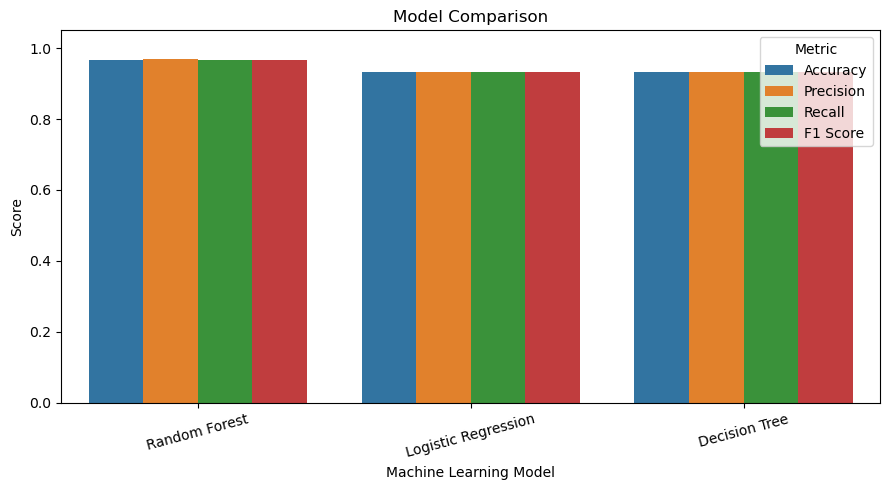

In [39]:
plt.figure(figsize=(9, 5))
results_plot = results_df.melt(
    id_vars="Model",
    value_vars=["Accuracy", "Precision", "Recall", "F1 Score"],
    var_name="Metric",
    value_name="Score"
)

sns.barplot(data=results_plot, x="Model", y="Score", hue="Metric")
plt.title("Model Comparison")
plt.xlabel("Machine Learning Model")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## Selecting the best model

In [40]:
best_model_name = results_df.iloc[0]["Model"]
best_pipeline = pipelines[best_model_name]

print("Best model based on test F1 Score:", best_model_name)
print("Accuracy:", round(results_df.iloc[0]["Accuracy"], 4))
print("Precision:", round(results_df.iloc[0]["Precision"], 4))
print("Recall:", round(results_df.iloc[0]["Recall"], 4))
print("F1 Score:", round(results_df.iloc[0]["F1 Score"], 4))

Best model based on test F1 Score: Random Forest
Accuracy: 0.9667
Precision: 0.9697
Recall: 0.9667
F1 Score: 0.9666


## Actual vs Predicted Species

### Generate predictions

In [41]:
y_pred = best_pipeline.predict(X_test)

comparison_df = pd.DataFrame({
    "Actual_Species": y_test.values,
    "Predicted_Species": y_pred
})

comparison_df["Correct"] = (
    comparison_df["Actual_Species"] == comparison_df["Predicted_Species"]
)

display(comparison_df.head(10))

,Actual_Species,Predicted_Species,Correct
0,Iris-versicolor,Iris-versicolor,True
1,Iris-versicolor,Iris-versicolor,True
2,Iris-virginica,Iris-virginica,True
3,Iris-setosa,Iris-setosa,True
4,Iris-virginica,Iris-virginica,True
5,Iris-versicolor,Iris-virginica,False
6,Iris-versicolor,Iris-versicolor,True
7,Iris-setosa,Iris-setosa,True
8,Iris-virginica,Iris-virginica,True
9,Iris-virginica,Iris-virginica,True


## Confusion Matrix

The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.


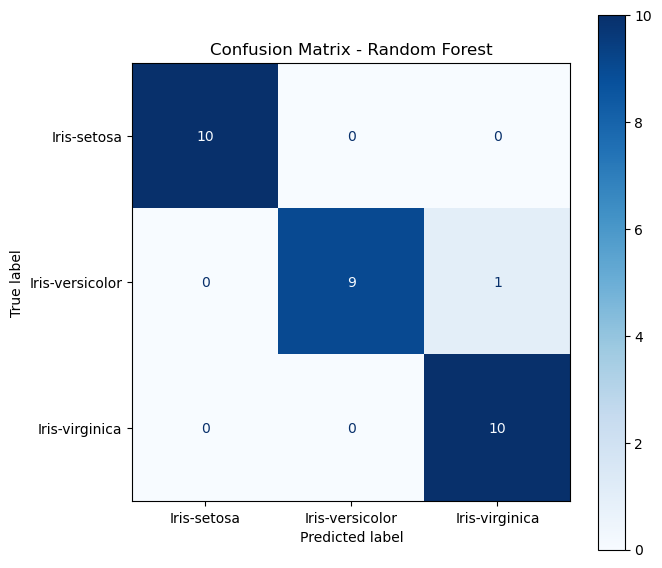

In [42]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred, labels=best_pipeline.classes_)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=best_pipeline.classes_
)

fig, ax = plt.subplots(figsize=(7, 6))
disp.plot(ax=ax, cmap="Blues")
plt.title(f"Confusion Matrix - {best_model_name}")
plt.tight_layout()
plt.show()

- The confusion matrix shows the number of correct and incorrect predictions for each Iris species.

## Classification Report

In [43]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred, zero_division=0))

                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       1.00      0.90      0.95        10
 Iris-virginica       0.91      1.00      0.95        10

       accuracy                           0.97        30
      macro avg       0.97      0.97      0.97        30
   weighted avg       0.97      0.97      0.97        30



## Saving the Trained model

- The complete pipeline is saved so that the same preprocessing and trained model can be reused in the application.

In [44]:
import os
import joblib

In [45]:
model_path = "iris_species_model_ML_Proj.pkl"

joblib.dump(best_pipeline, model_path)

print("Model saved successfully!")
print("Saved at:", model_path)


Model saved successfully!
Saved at: iris_species_model_ML_Proj.pkl


## Verify that the saved model works:

In [47]:
loaded_model = joblib.load(model_path)

sample_predictions = loaded_model.predict(X_test.head(5))

print("Predictions from the saved model: ")
print(sample_predictions)

Predictions from the saved model: 
['Iris-versicolor' 'Iris-versicolor' 'Iris-virginica' 'Iris-setosa'
 'Iris-virginica']


## Building the Gradio application

In [48]:
import gradio as gr

In [51]:
model_path = "iris_species_model_ML_Proj.pkl"

if os.path.exists(model_path):
    model = joblib.load(model_path)
    print("Saved model loaded successfully!")
else:
    model = best_pipeline
    print("Using the trained best_pipeline model.")

Saved model loaded successfully!


In [50]:
def predict_iris_species(
    sepal_length,
    sepal_width,
    petal_length,
    petal_width
):
    input_data = pd.DataFrame([{
        "sepal_length": float(sepal_length),
        "sepal_width": float(sepal_width),
        "petal_length": float(petal_length),
        "petal_width": float(petal_width)
    }])

    predicted_species = model.predict(input_data)[0]

    return f"Predicted Iris Species: {predicted_species}"

In [52]:
iris_app = gr.Interface(
    fn=predict_iris_species,

    inputs=[
        gr.Number(
            label="Sepal Length (cm)",
            value=5.1
        ),
        gr.Number(
            label="Sepal Width (cm)",
            value=3.5
        ),
        gr.Number(
            label="Petal Length (cm)",
            value=1.4
        ),
        gr.Number(
            label="Petal Width (cm)",
            value=0.2
        )
    ],

    outputs=gr.Textbox(label="Predicted Species"),

    title="🌸 Iris Flower Species Classification",

    description=(
        "Enter the sepal and petal measurements of an Iris flower "
        "to predict its species using machine learning."
    ),

    examples=[
        [5.1, 3.5, 1.4, 0.2],
        [6.0, 2.9, 4.5, 1.5],
        [6.5, 3.0, 5.2, 2.0]
    ]
)

print("Gradio interface created successfully!")

Gradio interface created successfully!


In [53]:
iris_app.launch(share=True)

* Running on local URL:  http://127.0.0.1:7861
* Running on public URL: https://9f27c267806d1023a6.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
